histogram of low number of reviews: to dr bachura. by duration in movie run time:  

# Movies Project Starter

Use this starter notebook for the BAN 5003 final project option: **The Movies Dataset / MovieLens ratings**.

##DISCLAIMER##

This is a fresh clone of the starter repo from Dr. Zu's BAN6003 and as such, many sections will be altered/changed/removed as needed for BAN5003. 

Run cells from top to bottom first. Then replace starter notes with your own project decisions, checks, and interpretation.

Start each milestone by reading the matching Canvas milestone assignment page. The Canvas page tells you exactly what evidence and submission items are required; this notebook gives you starter spaces to build that work.



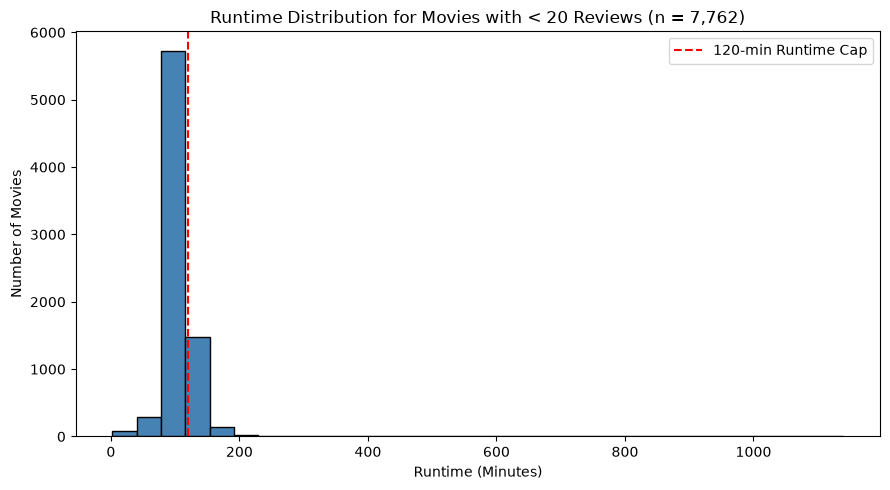

In [10]:

rating_counts = (
    ratings.groupby("movieId", as_index=False)
    .agg(rating_count=("rating", "count"))
)

# 2. Join directly on movieId if present in movies_metadata, otherwise map via links.csv
if "movieId" in movies.columns:
    movie_reviews = movies[["movieId", "title", "runtime"]].merge(
        rating_counts, on="movieId", how="left", validate="one_to_one"
    )
else:
    links = pd.read_csv("../data/links.csv")
    id_col = "tmdbId" if "tmdbId" in movies.columns else "id"
    movie_reviews = (
        movies[[id_col, "title", "runtime"]]
        .merge(links[["movieId", "tmdbId"]], left_on=id_col, right_on="tmdbId", how="left")
        .merge(rating_counts, on="movieId", how="left")
    )

# 3. Fill movies with 0 ratings and filter for valid runtime + low review count (< 20)
movie_reviews["rating_count"] = movie_reviews["rating_count"].fillna(0)
low_reviews = movie_reviews[(movie_reviews["runtime"] > 0) & (movie_reviews["rating_count"] < 20)]

# 4. Plot the histogram
plt.figure(figsize=(9, 5))
plt.hist(low_reviews["runtime"], bins=30, edgecolor="black", color="steelblue")
plt.axvline(120, color="red", linestyle="--", linewidth=1.5, label="120-min Runtime Cap")
plt.title(f"Runtime Distribution for Movies with < 20 Reviews (n = {len(low_reviews):,})")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")
plt.legend()
plt.tight_layout()
plt.show()


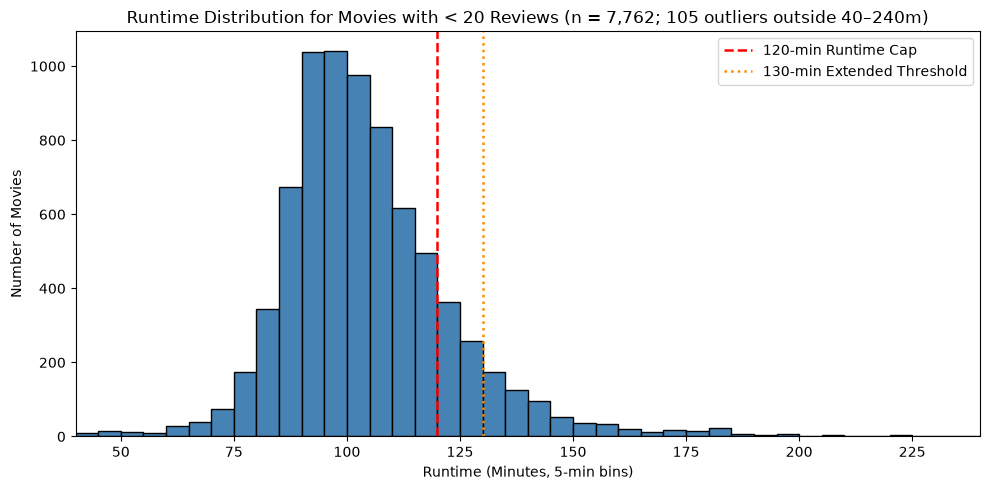

In [ ]:
import numpy as np

# Focus on standard theatrical range (40 to 240 mins) with 5-minute bins
bins = np.arange(40, 245, 5)
outliers = low_reviews[(low_reviews["runtime"] < 40) | (low_reviews["runtime"] > 240)]

plt.figure(figsize=(10, 5))
plt.hist(low_reviews["runtime"], bins=bins, edgecolor="black", color="steelblue")
plt.axvline(120, color="red", linestyle="--", linewidth=1.8, label="120-min Runtime Cap")
plt.axvline(130, color="darkorange", linestyle=":", linewidth=1.8, label="130-min Extended Threshold")
plt.xlim(40, 240)
plt.title(f"Runtime for movies with < 20 reviews in 10 minute categories)
plt.xlabel("Runtime (Minutes, 5-min bins)")
plt.ylabel("Number of Movies")
plt.legend()
plt.tight_layout()
plt.show()

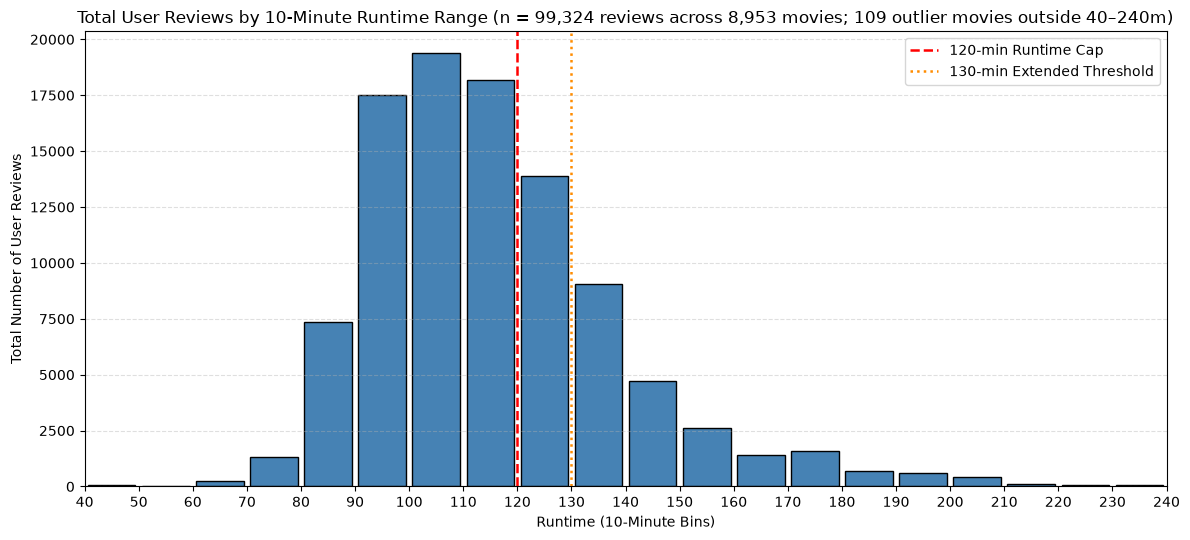

In [12]:

valid_movies = movie_reviews[movie_reviews["runtime"] > 0].copy()

# 10-minute bins from 40 to 240 minutes
bins = np.arange(40, 250, 10)
in_range = valid_movies[(valid_movies["runtime"] >= 40) & (valid_movies["runtime"] <= 240)]
outliers = valid_movies[(valid_movies["runtime"] < 40) | (valid_movies["runtime"] > 240)]

plt.figure(figsize=(12, 5.5))

# Using weights='rating_count' sums total reviews in each 10-minute runtime bin
plt.hist(
    in_range["runtime"],
    bins=bins,
    weights=in_range["rating_count"],
    edgecolor="black",
    color="steelblue",
    rwidth=0.88
)

# Reference lines for your 120-min cap and 130-min extended threshold
plt.axvline(120, color="red", linestyle="--", linewidth=1.8, label="120-min Runtime Cap")
plt.axvline(130, color="darkorange", linestyle=":", linewidth=1.8, label="130-min Extended Threshold")

plt.xticks(bins)
plt.xlim(40, 240)
plt.title(
    f"Total User Reviews by 10-Minute Runtime Range "
    f"(n = {int(in_range['rating_count'].sum()):,} reviews across {len(in_range):,} movies; "
    f"{len(outliers)} outlier movies outside 40–240m)"
)
plt.xlabel("Runtime (10-Minute Bins)")
plt.ylabel("Total Number of User Reviews")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

# Save high-res image for your morning email
plt.savefig("../outputs/reviews_by_runtime_10min.png", dpi=300, bbox_inches="tight")
plt.show()


## Before You Start: Key Project Hints

This dataset mixes movie-level tables and rating-event-level data. The key skill is controlling granularity.

- A common final ABT is **one row per movie**.
- Do **not** directly merge raw `ratings` into `movies` and assume the result is still one row per movie.
- Aggregate ratings to `movieId` first, then merge the rating summary into the movie table.
- Use `movieId` for ratings and `tmdbId` for curated credits/keywords.
- Average rating is unstable for movies with very few ratings. Use a minimum rating-count threshold before modeling.
- Be careful about leakage: post-release fields such as revenue, popularity, vote count, or rating count may not be valid if your question is pre-release prediction.

## Setup

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "README.md").exists() and (REPO_ROOT.parent / "README.md").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
REPORTS_DIR = REPO_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)


## Load Data

Read each provided table. Keep the original row meaning in mind before joining tables.

In [6]:
movies = pd.read_csv(DATA_DIR / 'movies_metadata.csv')
ratings = pd.read_csv(DATA_DIR / 'ratings.csv', parse_dates=['rating_datetime'])
links = pd.read_csv(DATA_DIR / 'links.csv')
credits = pd.read_csv(DATA_DIR / 'credits_curated.csv')
keywords = pd.read_csv(DATA_DIR / 'keywords_curated.csv')

tables = {
    'movies': movies,
    'ratings': ratings,
    'links': links,
    'credits': credits,
    'keywords': keywords,
}

## Basic Data Profile

Use this section for your first pass through row counts, columns, data types, missingness, duplicates, and suspicious values.

In [ ]:
for name, df in tables.items():
    print(f'\n{name}: {df.shape[0]:,} rows x {df.shape[1]:,} columns')
    display(df.head(3))

In [ ]:
profile_rows = []
for name, df in tables.items():
    profile_rows.append({
        'table': name,
        'rows': len(df),
        'columns': df.shape[1],
        'duplicate_rows': int(df.duplicated().sum()),
        'missing_cells': int(df.isna().sum().sum()),
    })
pd.DataFrame(profile_rows)

### Key and Granularity Audit

Use the expected key for each table before planning joins. `ratings` is the exception: its row meaning is a user-movie rating event, so check the combined `userId`-`movieId` key rather than expecting `movieId` alone to be unique. `links` is a crosswalk; because `movies` already contains both IDs, use it for validation unless your analysis needs one of its fields.


In [ ]:
key_audit = pd.DataFrame([
    {"table": "movies", "expected_key": "movieId", "duplicate_keys": movies["movieId"].duplicated().sum(), "missing_key_values": movies["movieId"].isna().sum()},
    {"table": "movies", "expected_key": "tmdbId", "duplicate_keys": movies["tmdbId"].duplicated().sum(), "missing_key_values": movies["tmdbId"].isna().sum()},
    {"table": "ratings", "expected_key": "userId + movieId", "duplicate_keys": ratings[["userId", "movieId"]].duplicated().sum(), "missing_key_values": ratings[["userId", "movieId"]].isna().sum().sum()},
    {"table": "links", "expected_key": "movieId", "duplicate_keys": links["movieId"].duplicated().sum(), "missing_key_values": links["movieId"].isna().sum()},
    {"table": "credits", "expected_key": "tmdbId", "duplicate_keys": credits["tmdbId"].duplicated().sum(), "missing_key_values": credits["tmdbId"].isna().sum()},
    {"table": "keywords", "expected_key": "tmdbId", "duplicate_keys": keywords["tmdbId"].duplicated().sum(), "missing_key_values": keywords["tmdbId"].isna().sum()},
])

key_audit


## Milestone 1 Starter: Initial Profile and Cleaning Plan

Complete this by the first project milestone.

Write notes on:

- Business problem and decision context
- Raw tables and row meaning
- Initial row and column counts
- Data type issues
- Missing values and duplicates
- Suspicious values
- Proposed target/outcome
- Early ethics or governance concerns

Important Movies notes:

- `movies` is movie-level, while `ratings` is user-movie rating-event-level.
- `credits` and `keywords` are curated movie-level tables connected by `tmdbId`.
- Budget and revenue may contain zero or missing-like values; describe this before using them.
- Decide whether your project is about audience ratings, catalog strategy, revenue, popularity, or genre/content patterns.

### Read the Canvas milestone page first

Before you start this section, read the matching Canvas milestone assignment page. The Canvas page is the authoritative checklist for what you need to submit, how the milestone is graded, and what evidence should appear in your notebook/report. Use this starter section as a workspace, not as a replacement for the Canvas instructions.



### Milestone 1 written workspace

Use this cell to draft the narrative required by the Canvas Milestone 1 page.

- Business or research question:
- Why this question matters:
- Tables/files used:
- Row meaning of each important table:
- Early data quality issues:
- Initial cleaning plan:
- Possible target/outcome:
- Ethics, privacy, or governance concerns:



In [ ]:
# Milestone 1 code workspace
# Add your additional profiling checks here.
# Examples: missingness by important columns, duplicate key checks, suspicious value checks.



In [ ]:
# Milestone 1 starter checks
for name, df in tables.items():
    print(f'\n{name}')
    display(df.dtypes.to_frame('dtype').head(20))
    display(df.isna().mean().sort_values(ascending=False).head(10).to_frame('missing_rate'))

## Milestone 2 Starter: Integration, Transformation, and Preliminary ABT

Build a preliminary ABT. State exactly what one row means, what keys define one row, and what tables were joined or aggregated.

Critical integration reminder:

Before creating a movie-level ABT, aggregate ratings. Examples include:

- average rating by `movieId`
- rating count by `movieId`
- rating standard deviation by `movieId`
- first and last rating date by `movieId`
- distinct user count by `movieId`

After merging, validate that `movieId` is not duplicated in the ABT.

### Read the Canvas milestone page first

Before you start this section, read the matching Canvas milestone assignment page. The Canvas page is the authoritative checklist for what you need to submit, how the milestone is graded, and what evidence should appear in your notebook/report. Use this starter section as a workspace, not as a replacement for the Canvas instructions.



### Milestone 2 written workspace

Use this cell to document the ABT design required by the Canvas Milestone 2 page.

- Final or preliminary unit of analysis:
- Primary key for one row:
- Tables aggregated before joining:
- Tables joined directly:
- Row-count validation after each major merge:
- New variables created:
- Remaining data quality concerns:



In [ ]:
# Milestone 2 code workspace
# Build or revise your ABT here.
# Add row-count checks and duplicate-key checks after each major merge.



In [ ]:
rating_summary = (
    ratings.groupby("movieId")
    .agg(
        user_rating_mean=("rating", "mean"),
        user_rating_count=("rating", "size"),
        user_rating_std=("rating", "std"),
        first_rating_date=("rating_datetime", "min"),
        last_rating_date=("rating_datetime", "max")
    )
    .reset_index()
)

abt = (
    movies
    .merge(rating_summary, on="movieId", how="left", validate="one_to_one")
    .merge(credits, on="tmdbId", how="left", validate="one_to_one")
    .merge(keywords, on="tmdbId", how="left", validate="one_to_one")
)

abt["has_revenue"] = (pd.to_numeric(abt["revenue"], errors="coerce") > 0).astype("Int64")
abt["rating_target_eligible"] = abt["user_rating_count"].ge(20)
abt["high_user_rating"] = (
    abt["user_rating_mean"].ge(3.75)
    .where(abt["rating_target_eligible"])
    .astype("Int64")
)


In [ ]:
abt_validation = pd.Series({
    "movie_rows_before_merges": len(movies),
    "abt_rows_after_merges": len(abt),
    "duplicate_movie_ids": abt["movieId"].duplicated().sum(),
    "duplicate_tmdb_ids": abt["tmdbId"].duplicated().sum(),
    "movies_with_rating_summary": abt["user_rating_count"].notna().sum(),
    "movies_eligible_for_rating_target": abt["high_user_rating"].notna().sum(),
})

display(abt_validation)
display(abt.head())
display(abt.isna().mean().sort_values(ascending=False).head(15).to_frame("missing_rate"))


### SQL Validation (Path A: Your Own Neon, or Path B: DuckDB)

The project milestone asks for SQL work that supports the workflow. You choose one of two paths:

- **Path A:** your own free Neon database. Upload your tables and query them with SQL.
- **Path B:** DuckDB, which runs SQL directly on pandas DataFrames, so no database server or extra database file is needed.

The notebook `module10_part2_project_sql_options.ipynb` in your Week 9-10 repository explains both paths and has cells marked `# COPY` that you can paste here. The example below uses Path B. The query below checks the movie-level ABT row count and key uniqueness, and a second query rebuilds one aggregation in SQL and compares it with the pandas result.

**Milestone 2 requirement:** include at least one SQL query on your own project data, using Path A or Path B. This cell is a starting example. Extend it with your own query, for example rebuild one aggregation or join from your ABT in SQL and compare the result with pandas. If you use Path A, commit the saved query results in `outputs/sql_results/` (never `.env`), so your notebook runs for the instructor.

In [ ]:
import duckdb

# DuckDB can query a pandas DataFrame by its variable name (here: abt).
sql_abt_check = duckdb.sql("""
    SELECT
        COUNT(*) AS abt_rows,
        COUNT(DISTINCT movieId) AS unique_movie_ids,
        CAST(SUM(CASE WHEN high_user_rating IS NULL THEN 1 ELSE 0 END) AS INTEGER) AS target_not_defined_rows
    FROM abt
""").df()
display(sql_abt_check)

# Key check: one row per movieId means the two counts must match.
assert sql_abt_check.loc[0, "abt_rows"] == sql_abt_check.loc[0, "unique_movie_ids"] == len(abt)

# One aggregation in SQL, compared with the same aggregation in pandas.
sql_by_eligibility = duckdb.sql("""
    SELECT
        rating_target_eligible,
        COUNT(*) AS movies,
        AVG(user_rating_mean) AS avg_user_rating
    FROM abt
    WHERE rating_target_eligible IS NOT NULL
    GROUP BY rating_target_eligible
    ORDER BY rating_target_eligible
""").df()

pandas_by_eligibility = (
    abt.groupby("rating_target_eligible")
    .agg(movies=("movieId", "size"), avg_user_rating=("user_rating_mean", "mean"))
    .reset_index()
    .sort_values("rating_target_eligible")
    .reset_index(drop=True)
)

display(sql_by_eligibility)
print("Counts match pandas:", (sql_by_eligibility["movies"].to_numpy() == pandas_by_eligibility["movies"].to_numpy()).all())
print("Averages match pandas:", np.allclose(
    sql_by_eligibility["avg_user_rating"].astype(float), pandas_by_eligibility["avg_user_rating"].astype(float), equal_nan=True
))

### Data Dictionary Starter

Complete the text fields for every column you keep in the final ABT. Remove unused columns before finalizing the dictionary so the documentation and exported ABT stay aligned.


In [ ]:
data_dictionary = pd.DataFrame({
    "column_name": abt.columns,
    "data_type": [str(abt[column].dtype) for column in abt.columns],
    "description": "",
    "source": "",
    "transformation_or_derivation": "",
    "notes_or_concerns": "",
})

# Hint: use .loc[] to document one column at a time, following the Week 11 pattern.
data_dictionary.head()


## Milestone 3 Starter: Prepared Dataset and Initial Model Application

Choose a target/outcome and features. Start simple. Your first model should be correct and interpretable before it becomes complex.

Modeling reminder:

- If you model `high_user_rating`, use only rows where that nullable target is defined; these movies have at least 20 ratings.
- State when the prediction is meant to occur. For a pre-release question, exclude post-release fields such as revenue, popularity, vote count, rating summaries, and rating dates.
- Do not interpret a rating model as proving artistic quality or causal effects.


### Read the Canvas milestone page first

Before you start this section, read the matching Canvas milestone assignment page. The Canvas page is the authoritative checklist for what you need to submit, how the milestone is graded, and what evidence should appear in your notebook/report. Use this starter section as a workspace, not as a replacement for the Canvas instructions.



### Milestone 3 written workspace

Use this cell to document the prepared dataset and initial model/analysis required by the Canvas Milestone 3 page.

- Target/outcome:
- Feature variables:
- Rows included/excluded and why:
- Train/test split or evaluation plan:
- Baseline model or analysis:
- Initial metrics/results:
- Interpretation limits:



In [ ]:
# Milestone 3 code workspace
# Suggested sequence:
# 1. State the prediction or analysis timing in markdown.
# 2. Filter to rows where your target is defined.
# 3. Select only features available at that time.
# 4. Check class balance or the target distribution.
# 5. Create a reproducible train/test split when modeling.
# 6. Fit a simple baseline and evaluate it on test data.


In [ ]:
# Example placeholder. Replace with your chosen target and feature set.
# target = 'your_target_column'
# features = ['feature_1', 'feature_2']
# model_df = abt[[target] + features].dropna()

abt.describe(include='all').T.head(25)

## Final Project Starter: Interpretation, Ethics, and Recommendations

Use this section to connect your analysis back to a business or research decision.

Address:

- Main finding
- What the model/analysis can and cannot support
- Limitations
- Ethics or responsible use concerns
- 2-3 cautious recommendations

### Read the Canvas final submission page first

Before completing this section, read the Canvas final submission assignment page. The Canvas page is the authoritative checklist for the final notebook, HTML report, required files, and submission format. Use this section to organize your final evidence and interpretation.



### Final report written workspace

Use this cell to draft the final interpretation required by the Canvas final submission page.

- Main finding:
- Evidence supporting the finding:
- Business or research implication:
- Limitations:
- Ethics/responsible use concerns:
- Recommendations:
- What you would improve with more time:



In [ ]:
# Final project code workspace
# Save final datasets, figures, or tables here when they are ready.
# Required filenames (final ABT and data dictionary):
# final_abt_path = OUTPUT_DIR / "movies_final_abt.csv"
# dictionary_path = OUTPUT_DIR / "movies_data_dictionary.csv"
# Suggested filename for model metrics:
# metrics_path = OUTPUT_DIR / "movies_model_metrics.csv"
# HTML report: after Restart & Run All, export with the nbconvert command in README.md
# (it creates reports/movies_project_starter.html).


In [ ]:
# Required outputs: save your final ABT and data dictionary with these exact file names.
# Uncomment these lines when your ABT and documentation are complete.
# abt.to_csv(OUTPUT_DIR / "movies_final_abt.csv", index=False)
# data_dictionary.to_csv(OUTPUT_DIR / "movies_data_dictionary.csv", index=False)

# Before final submission, restart the kernel, run all cells, and export the notebook to HTML
# (see "Export the HTML Report" in README.md).


### DuckDB on the Exported ABT File

DuckDB can also query a CSV file directly by its path, without loading it into pandas first. After you save the final ABT above, this check confirms that the exported file has the same row count and unique keys as the `abt` DataFrame.

In [ ]:
final_abt_file = OUTPUT_DIR / "movies_final_abt.csv"

if final_abt_file.exists():
    csv_abt_check = duckdb.sql(f"""
        SELECT
            COUNT(*) AS file_rows,
            COUNT(DISTINCT movieId) AS unique_keys
        FROM read_csv('{final_abt_file.as_posix()}')
    """).df()
    display(csv_abt_check)
    print("Exported file matches abt:", csv_abt_check.loc[0, "file_rows"] == len(abt) == abt["movieId"].nunique())
else:
    print("Export the final ABT first (uncomment the to_csv line above), then rerun this cell.")

## AI Use Disclosure

Keep this cell at the end of your final notebook. State which AI tools you used and what you used them for (for example, debugging an error or explaining a function). If you did not use any AI tools, write "None".

**AI tools used and purpose:** Type your answer here.